# Tugas: Klasifikasi Kematangan Buah (Perbandingan Color Space)
Di dalam eksperimen ini, kita akan membandingkan bagaimana ruang warna (color space) **RGB/Grayscale**, **HSV**, dan **CIELAB** merepresentasikan berbagai tahapan kematangan buah pisang (mentah/unripe, matang/ripe, terlalu matang/overripe).

**Tujuan**: Menemukan *color space* mana yang menonjolkan fitur terbaik untuk membedakan ketiga kelas tersebut, lalu mempraktikkan logika klasifikasi berbasis persentase piksel (Rule-Based Classification).

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

def show_three(img1, img2, img3, title1="Unripe", title2="Ripe", title3="Overripe", cmap=None):
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(axs, [img1, img2, img3], [title1, title2, title3]):
        if cmap:
            ax.imshow(img, cmap=cmap)
        else:
            ax.imshow(img)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 1. Load Data Gambar Asli
Kita muat dataset gambar pisang dan konversi BGR ke RGB agar Matplotlib menampilkannya dengan warna yang benar.

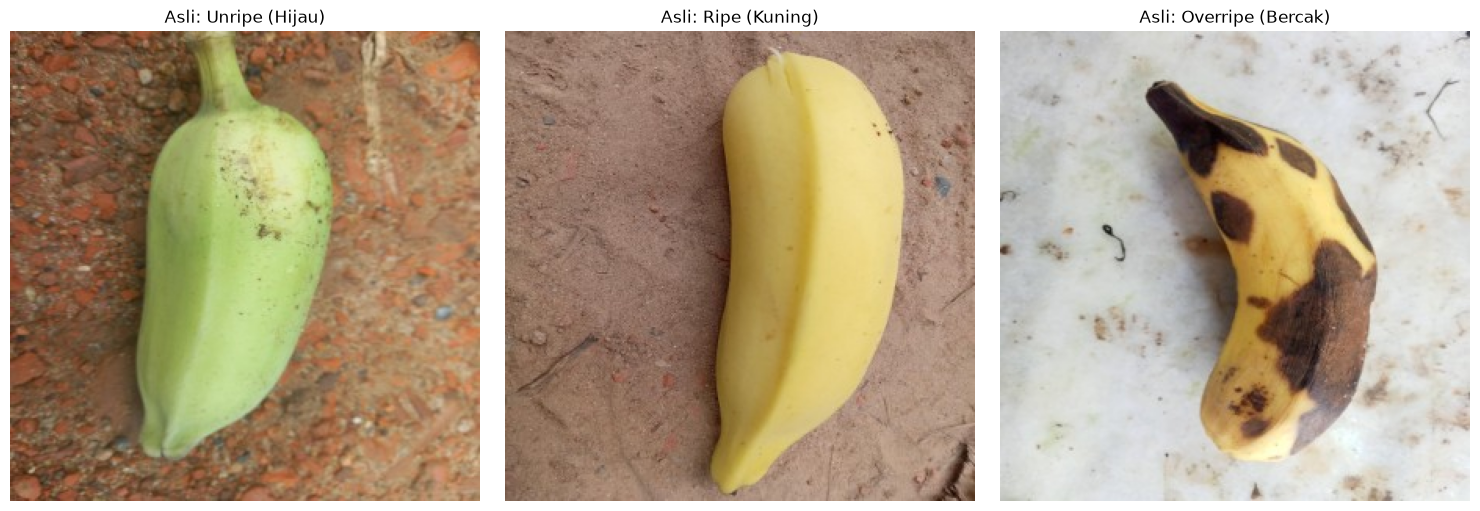

In [7]:
# Load gambar
unripe = cv2.imread('../assets/banana_unripe.jpg')
ripe = cv2.imread('../assets/banana_ripe.jpg')
overripe = cv2.imread('../assets/banana_overripe.jpg')

if unripe is None or ripe is None or overripe is None:
    print("Error: Gagal memuat gambar. Cek kembali path filenya.")
else:
    # Konversi ke RGB
    unripe_rgb = cv2.cvtColor(unripe, cv2.COLOR_BGR2RGB)
    ripe_rgb = cv2.cvtColor(ripe, cv2.COLOR_BGR2RGB)
    overripe_rgb = cv2.cvtColor(overripe, cv2.COLOR_BGR2RGB)

    show_three(unripe_rgb, ripe_rgb, overripe_rgb, "Asli: Unripe (Hijau)", "Asli: Ripe (Kuning)", "Asli: Overripe (Bercak)")

### 2. Flow 1: RGB -> Grayscale -> Binary Thresholding
Mari kita lihat apakah intensitas Grayscale bisa membedakan kematangan. Kita gunakan *inverted binary threshold* untuk mendeteksi "bercak hitam/gelap".

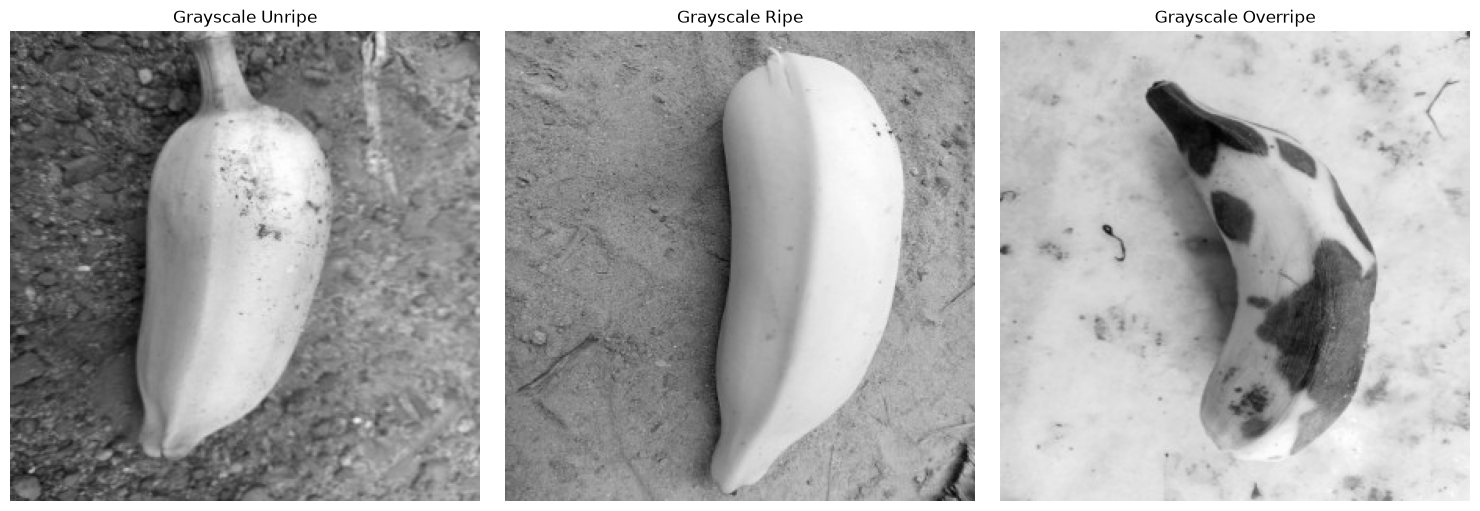

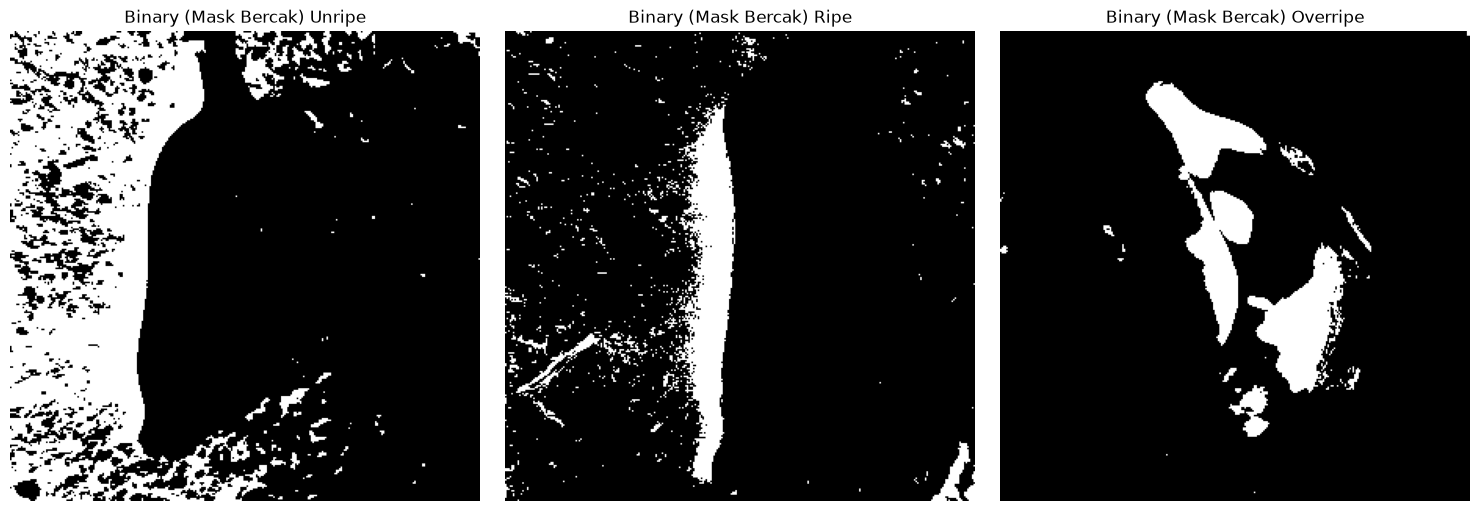

In [8]:
if unripe is not None:
    # Konversi ke Grayscale
    unripe_gray = cv2.cvtColor(unripe, cv2.COLOR_BGR2GRAY)
    ripe_gray = cv2.cvtColor(ripe, cv2.COLOR_BGR2GRAY)
    overripe_gray = cv2.cvtColor(overripe, cv2.COLOR_BGR2GRAY)

    show_three(unripe_gray, ripe_gray, overripe_gray, "Grayscale Unripe", "Grayscale Ripe", "Grayscale Overripe", cmap='gray')

    # Binary Thresholding: Piksel yang lebih gelap dari 100 menjadi putih (255), sisanya hitam (0)
    _, thresh_unripe = cv2.threshold(unripe_gray, 100, 255, cv2.THRESH_BINARY_INV)
    _, thresh_ripe = cv2.threshold(ripe_gray, 100, 255, cv2.THRESH_BINARY_INV)
    _, thresh_overripe = cv2.threshold(overripe_gray, 100, 255, cv2.THRESH_BINARY_INV)

    show_three(thresh_unripe, thresh_ripe, thresh_overripe, "Binary (Mask Bercak) Unripe", "Binary (Mask Bercak) Ripe", "Binary (Mask Bercak) Overripe", cmap='gray')

**Observasi (Grayscale/Binary)**: 
Bisa dilihat bahwa teknik ini **SANGAT SUKSES** mengisolasi bercak hitam pada pisang *overripe*! Namun, gagal total membedakan antara pisang hijau (unripe) dan kuning (ripe) karena nilai terang/gelapnya mirip.

### 3. Flow 2: RGB -> HSV (Hue, Saturation, Value)
HSV memisahkan warna murni (Hue) dari pencahayaan. Mari fokus ke *channel* **Hue**.

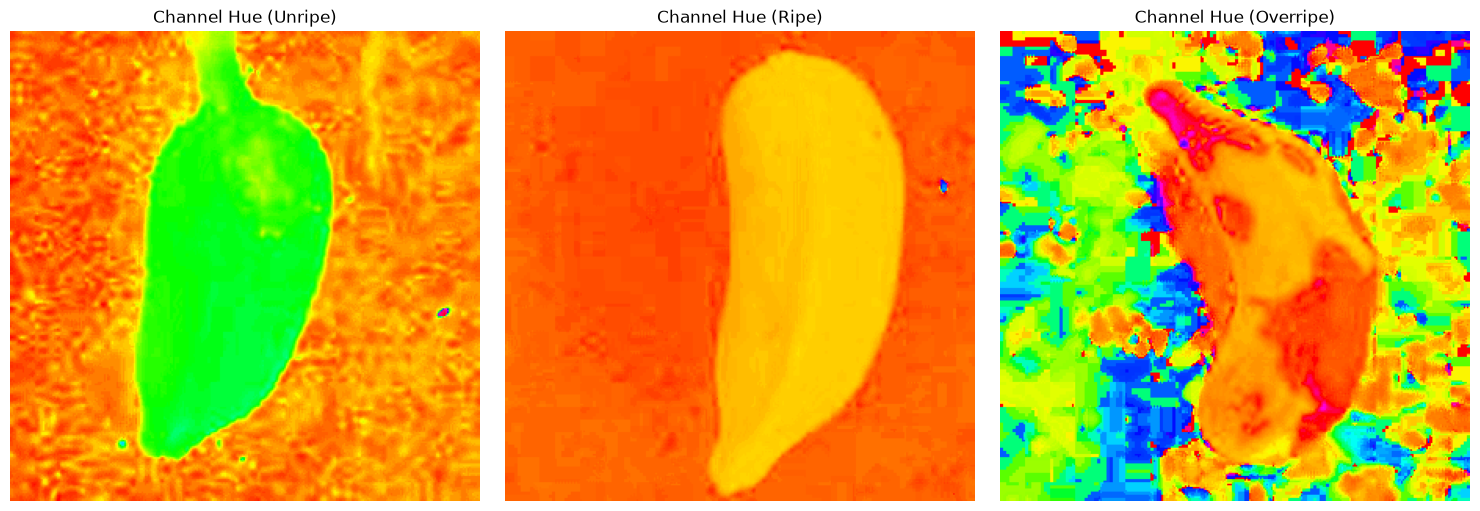

In [9]:
if unripe is not None:
    # Konversi ke HSV
    unripe_hsv = cv2.cvtColor(unripe, cv2.COLOR_BGR2HSV)
    ripe_hsv = cv2.cvtColor(ripe, cv2.COLOR_BGR2HSV)
    overripe_hsv = cv2.cvtColor(overripe, cv2.COLOR_BGR2HSV)

    # Ekstrak channel Hue (Indeks 0)
    h_unripe = unripe_hsv[:,:,0]
    h_ripe = ripe_hsv[:,:,0]
    h_overripe = overripe_hsv[:,:,0]

    show_three(h_unripe, h_ripe, h_overripe, "Channel Hue (Unripe)", "Channel Hue (Ripe)", "Channel Hue (Overripe)", cmap='hsv')

**Observasi (HSV)**: 
Sumbu Hue dengan sangat jelas memisahkan kelompok spektrum warna hijau pada pisang Unripe dengan kelompok warna kuning kemerahan pada pisang Ripe.

### 4. Flow 3: RGB -> CIELAB (L*a*b*)
Meniru mata manusia.
- **L***: Lightness (kecerahan)
- **a***: Sumbu Hijau (negatif) ke Merah (positif)
- **b***: Sumbu Biru (negatif) ke Kuning (positif)

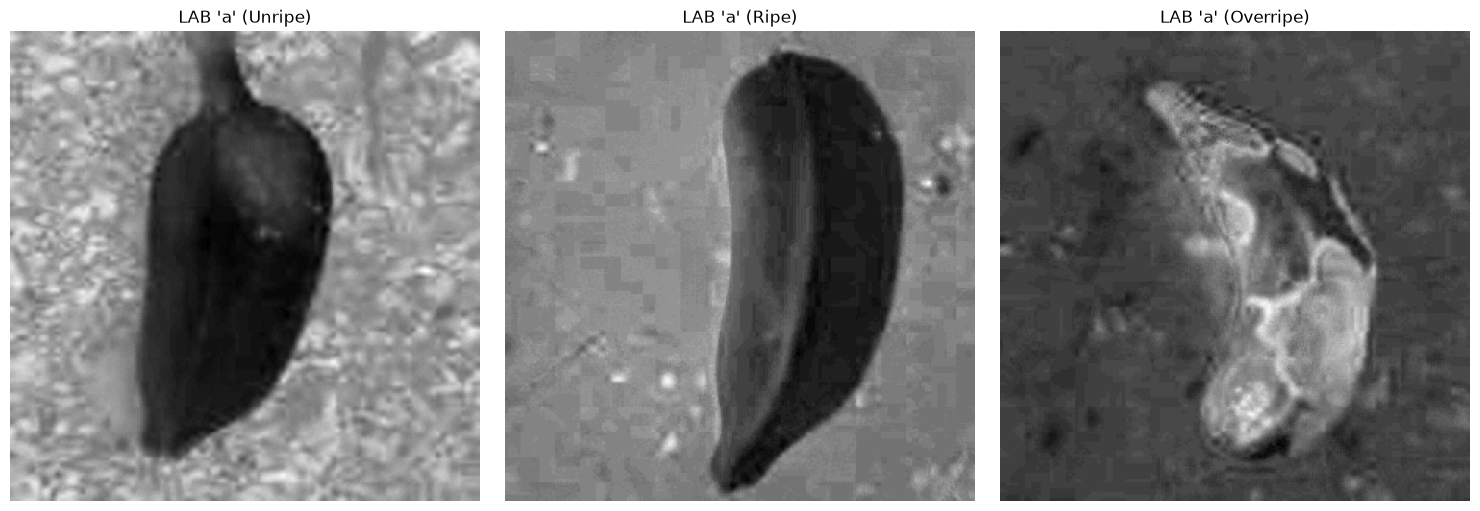

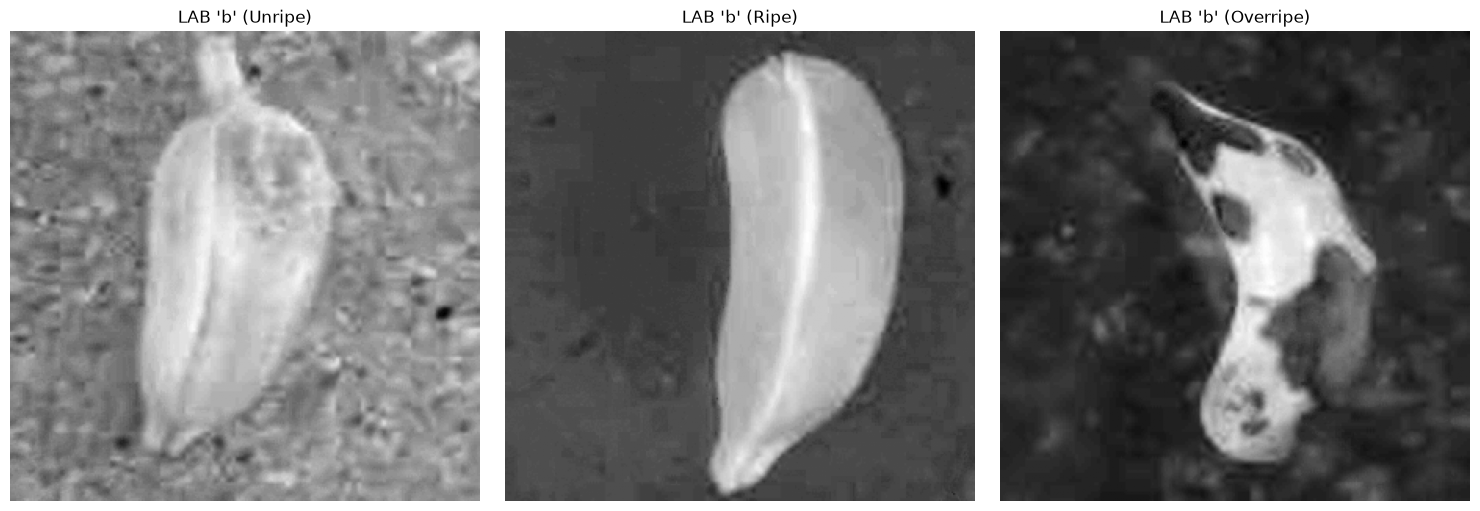

In [10]:
if unripe is not None:
    # Konversi ke LAB
    unripe_lab = cv2.cvtColor(unripe, cv2.COLOR_BGR2LAB)
    ripe_lab = cv2.cvtColor(ripe, cv2.COLOR_BGR2LAB)
    overripe_lab = cv2.cvtColor(overripe, cv2.COLOR_BGR2LAB)

    # Ekstrak channel 'a' (Hijau ke Merah)
    # Di OpenCV, nilai digeser 0-255. Nilai kecil (<128) berarti cenderung Hijau.
    a_unripe = unripe_lab[:,:,1]
    a_ripe = ripe_lab[:,:,1]
    a_overripe = overripe_lab[:,:,1]

    show_three(a_unripe, a_ripe, a_overripe, "LAB 'a' (Unripe)", "LAB 'a' (Ripe)", "LAB 'a' (Overripe)", cmap='gray')
    
    # Ekstrak channel 'b' (Biru ke Kuning)
    # Nilai besar (>128) berarti cenderung Kuning.
    b_unripe = unripe_lab[:,:,2]
    b_ripe = ripe_lab[:,:,2]
    b_overripe = overripe_lab[:,:,2]
    
    show_three(b_unripe, b_ripe, b_overripe, "LAB 'b' (Unripe)", "LAB 'b' (Ripe)", "LAB 'b' (Overripe)", cmap='gray')

### 5. Praktik: Simulasi Klasifikasi OVERRIPE dengan ROI (Region of Interest)
**Masalah Sebelumnya**: Background gambar ternyata bukan putih bersih (ada pasir, tanah merah, dan marmer). Teknik thresholding biasa mengira *background* tersebut adalah bagian dari pisang!

**Solusi (ROI)**: Karena kita tahu pisangnya selalu berada di tengah gambar, kita akan membuat *mask* berbentuk elips (Region of Interest) di tengah gambar. Kita hanya akan menghitung bercak di dalam elips tersebut.

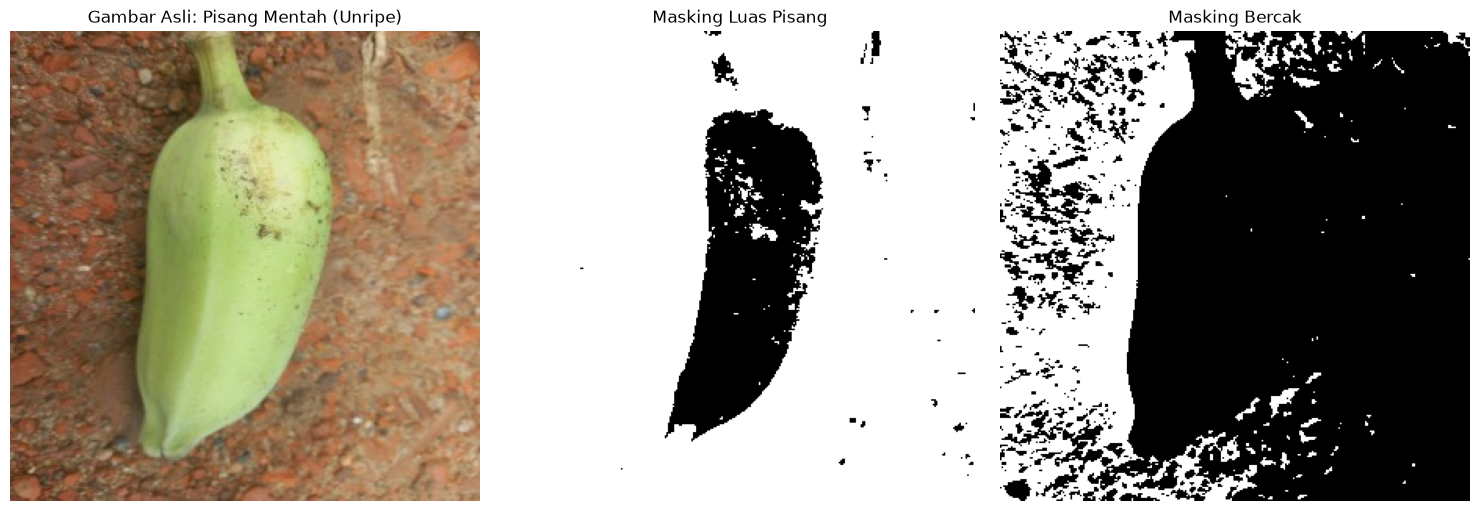

--- Hasil Analisis Pisang Mentah (Unripe) ---
Total Piksel Area Pisang : 77528 px
Total Piksel Bercak Hitam: 25177 px
Rasio Luas Bercak        : 32.47%
KESIMPULAN KELAS         : OVERRIPE (Terlalu Matang)



In [ ]:
def check_overripe_roi(image, name="Pisang"):
    height, width = image.shape[:2]
    
    # 1. Buat Mask ROI (Elips di tengah gambar)
    roi_mask = np.zeros((height, width), dtype=np.uint8)
    cv2.ellipse(roi_mask, (width//2, height//2), (70, 110), 0, 0, 360, 255, -1)
    
    # 2. Ambil channel Value (V) dari HSV untuk deteksi gelap yang lebih stabil
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    _, _, v = cv2.split(hsv)
    
    # 3. Masking Bercak Gelap (Value < 100)
    _, dark_mask = cv2.threshold(v, 100, 255, cv2.THRESH_BINARY_INV)
    
    # 4. Gabungkan ROI dan Bercak (Hanya ambil bercak yang ada di dalam elips)
    spot_mask = cv2.bitwise_and(dark_mask, roi_mask)
    
    total_banana_pixels = cv2.countNonZero(roi_mask)
    total_spot_pixels = cv2.countNonZero(spot_mask)
    
    # Visualisasi
    show_three(cv2.cvtColor(image, cv2.COLOR_BGR2RGB), roi_mask, spot_mask, 
               f"Asli: {name}", "Mask ROI (Fokus)", "Bercak Terdeteksi", cmap='gray')
    
    # Hitung Persentase Luas
    ratio = (total_spot_pixels / total_banana_pixels) * 100
    
    # Rule Klasifikasi (Ambang batas disesuaikan)
    status = "OVERRIPE (Terlalu Matang)" if ratio > 15.0 else "TIDAK OVERRIPE"
    
    print(f"--- Hasil Analisis {name} ---")
    print(f"Total Piksel Fokus (ROI) : {total_banana_pixels} px")
    print(f"Total Piksel Bercak Hitam: {total_spot_pixels} px")
    print(f"Rasio Luas Bercak        : {ratio:.2f}%")
    print(f"KESIMPULAN KELAS         : {status}")
    print("==========================================\n")

# Eksekusi untuk ketiga gambar
if unripe is not None:
    check_overripe_roi(unripe, "Pisang Mentah (Unripe)")
    check_overripe_roi(ripe, "Pisang Matang (Ripe)")
    check_overripe_roi(overripe, "Pisang Terlalu Matang (Overripe)")
